In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('/content/LIC_Insurance_Practice_Dataset.csv')

In [3]:
df.head()

,Customer_ID,Age,Gender,City,Policy_Type,Policy_ID,Premium_Amount,Sum_Assured,Policy_Term,Payment_Mode,Policy_Status,Claim_Amount
0,CUST001,25,Male,Trichy,Jeevan Anand,LICP0001,14151,500000,30,Half-Yearly,Active,481136
1,CUST002,55,Female,Salem,Term Insurance,LICP0002,34328,1500000,15,Yearly,Active,0
2,CUST003,50,Female,Trichy,Jeevan Anand,LICP0003,8385,500000,30,Half-Yearly,Active,0
3,CUST004,40,Female,Madurai,Jeevan Anand,LICP0004,15412,1000000,15,Monthly,Active,0
4,CUST005,40,Male,Bengaluru,Endowment,LICP0005,15696,500000,20,Yearly,Active,0


In [4]:
df.shape

(50, 12)

In [5]:
df.columns

Index(['Customer_ID', 'Age', 'Gender', 'City', 'Policy_Type', 'Policy_ID',
       'Premium_Amount', 'Sum_Assured', 'Policy_Term', 'Payment_Mode',
       'Policy_Status', 'Claim_Amount'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer_ID     50 non-null     object
 1   Age             50 non-null     int64 
 2   Gender          50 non-null     object
 3   City            50 non-null     object
 4   Policy_Type     50 non-null     object
 5   Policy_ID       50 non-null     object
 6   Premium_Amount  50 non-null     int64 
 7   Sum_Assured     50 non-null     int64 
 8   Policy_Term     50 non-null     int64 
 9   Payment_Mode    50 non-null     object
 10  Policy_Status   50 non-null     object
 11  Claim_Amount    50 non-null     int64 
dtypes: int64(5), object(7)
memory usage: 4.8+ KB


In [8]:
df.describe()

,Age,Premium_Amount,Sum_Assured,Policy_Term,Claim_Amount
count,50.000000,50.000000,5.000000e+01,50.000000,50.000000
mean,44.900000,18878.860000,6.650000e+05,19.700000,81467.220000
std,12.565339,13060.984161,3.877262e+05,6.881653,162727.828093
min,23.000000,3486.000000,2.000000e+05,10.000000,0.000000
25%,36.250000,8055.000000,3.000000e+05,15.000000,0.000000
50%,45.000000,15423.000000,5.000000e+05,20.000000,0.000000
75%,55.750000,29448.250000,1.000000e+06,25.000000,0.000000
max,64.000000,46763.000000,1.500000e+06,30.000000,481136.000000


In [9]:
df.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
City,0
Policy_Type,0
Policy_ID,0
Premium_Amount,0
Sum_Assured,0
Policy_Term,0
Payment_Mode,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [12]:
df = df.drop_duplicates()

In [13]:
df.dtypes

,0
Customer_ID,object
Age,int64
Gender,object
City,object
Policy_Type,object
Policy_ID,object
Premium_Amount,int64
Sum_Assured,int64
Policy_Term,int64
Payment_Mode,object


In [14]:
df['Policy_Status'].value_counts()

,count
Policy_Status,
Active,44
Lapsed,6


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer_ID     50 non-null     object
 1   Age             50 non-null     int64 
 2   Gender          50 non-null     object
 3   City            50 non-null     object
 4   Policy_Type     50 non-null     object
 5   Policy_ID       50 non-null     object
 6   Premium_Amount  50 non-null     int64 
 7   Sum_Assured     50 non-null     int64 
 8   Policy_Term     50 non-null     int64 
 9   Payment_Mode    50 non-null     object
 10  Policy_Status   50 non-null     object
 11  Claim_Amount    50 non-null     int64 
dtypes: int64(5), object(7)
memory usage: 4.8+ KB


In [16]:
total_customers = df['Customer_ID'].nunique()

print("Total Customers:", total_customers)

Total Customers: 50


In [17]:
total_premium = df['Premium_Amount'].sum()

print("Total Premium:", total_premium)

Total Premium: 943943


In [18]:
average_age = df['Age'].mean()

print("Average Customer Age:", average_age)

Average Customer Age: 44.9


In [19]:
total_sum_assured = df['Sum_Assured'].sum()

print("Total Sum Assured:", total_sum_assured)

Total Sum Assured: 33250000


In [20]:
total_claim = df['Claim_Amount'].sum()

print("Total Claim Amount:", total_claim)

Total Claim Amount: 4073361


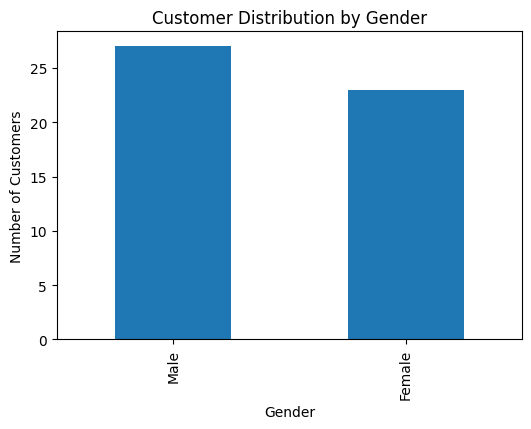

In [21]:
gender_count = df['Gender'].value_counts()

plt.figure(figsize=(6,4))

gender_count.plot(kind='bar')

plt.title('Customer Distribution by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

In [22]:
policy_count = df['Policy_Type'].value_counts()

print(policy_count)

Policy_Type
Jeevan Anand      15
Term Insurance    14
Endowment         12
Money Back         8
Child Plan         1
Name: count, dtype: int64


In [23]:
status_count = df['Policy_Status'].value_counts()

print(status_count)

Policy_Status
Active    44
Lapsed     6
Name: count, dtype: int64


In [24]:
city_customers = df.groupby('City')['Customer_ID'].nunique().sort_values(ascending=False)

print(city_customers)

City
Trichy        10
Bengaluru      9
Coimbatore     8
Chennai        5
Erode          5
Tiruppur       5
Salem          4
Madurai        4
Name: Customer_ID, dtype: int64


In [25]:
premium_analysis = df.groupby('Policy_Type')['Premium_Amount'].sum().sort_values(ascending=False)

print(premium_analysis)

Policy_Type
Term Insurance    344953
Jeevan Anand      292605
Endowment         163572
Money Back        100284
Child Plan         42529
Name: Premium_Amount, dtype: int64


In [26]:
payment_analysis = df.groupby('Payment_Mode')['Premium_Amount'].mean()

print(payment_analysis)

Payment_Mode
Half-Yearly    15073.250000
Monthly        21154.875000
Quarterly      19446.588235
Yearly         20248.692308
Name: Premium_Amount, dtype: float64


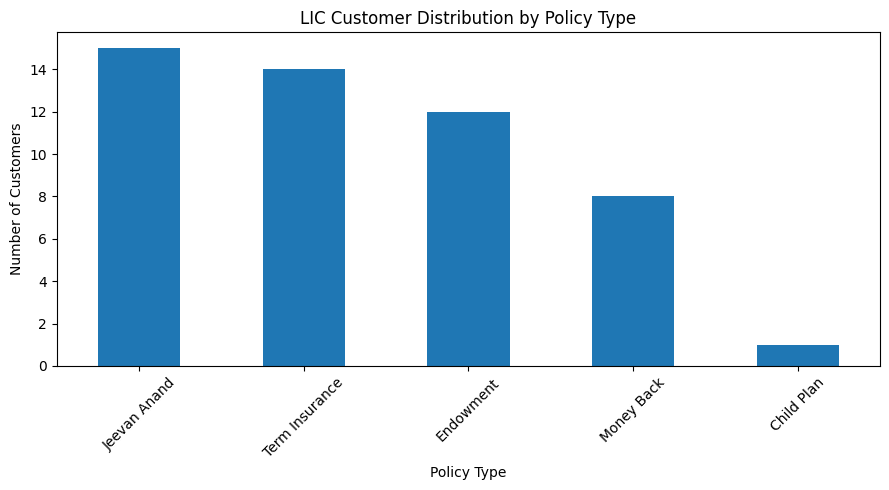

In [27]:
plt.figure(figsize=(9,5))

policy_count.plot(kind='bar')

plt.title('LIC Customer Distribution by Policy Type')
plt.xlabel('Policy Type')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

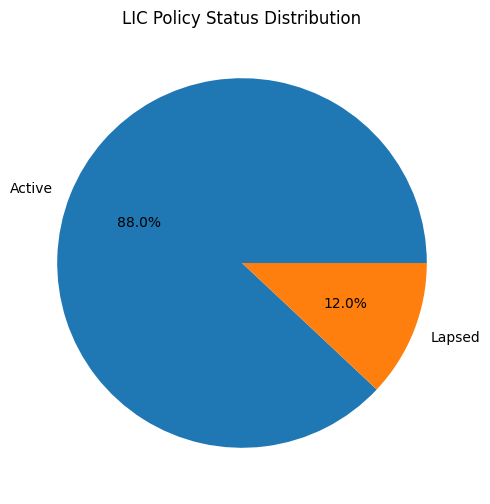

In [28]:
plt.figure(figsize=(6,6))

status_count.plot(kind='pie', autopct='%1.1f%%')

plt.title('LIC Policy Status Distribution')
plt.ylabel('')
plt.show()

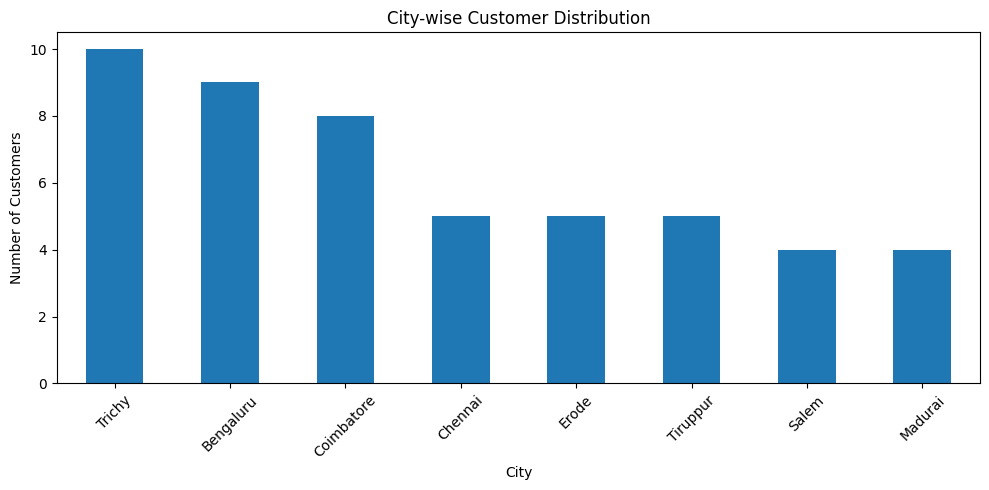

In [29]:
plt.figure(figsize=(10,5))

city_customers.plot(kind='bar')

plt.title('City-wise Customer Distribution')
plt.xlabel('City')
plt.ylabel('Number of Customers')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

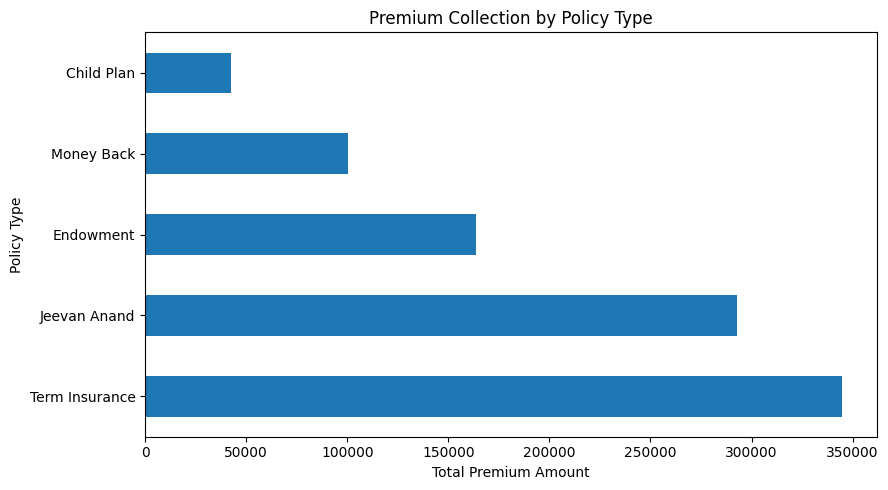

In [30]:
plt.figure(figsize=(9,5))

premium_analysis.plot(kind='barh')

plt.title('Premium Collection by Policy Type')
plt.xlabel('Total Premium Amount')
plt.ylabel('Policy Type')
plt.tight_layout()
plt.show()

In [31]:
total_claims = (df['Claim_Amount'] > 0).sum()

total_claim_amount = df['Claim_Amount'].sum()

average_claim = df.loc[df['Claim_Amount'] > 0, 'Claim_Amount'].mean()

print("Number of Claims:", total_claims)
print("Total Claim Amount:", total_claim_amount)
print("Average Claim Amount:", average_claim)

Number of Claims: 11
Total Claim Amount: 4073361
Average Claim Amount: 370305.54545454547


In [32]:
kpi_summary = pd.DataFrame({
    'Metric': [
        'Total Customers',
        'Total Policies',
        'Total Premium',
        'Total Sum Assured',
        'Active Policies',
        'Lapsed Policies',
        'Total Claims',
        'Total Claim Amount'
    ],
    'Value': [
        df['Customer_ID'].nunique(),
        df['Policy_ID'].nunique(),
        df['Premium_Amount'].sum(),
        df['Sum_Assured'].sum(),
        (df['Policy_Status'] == 'Active').sum(),
        (df['Policy_Status'] == 'Lapsed').sum(),
        (df['Claim_Amount'] > 0).sum(),
        df['Claim_Amount'].sum()
    ]
})

kpi_summary

,Metric,Value
0,Total Customers,50
1,Total Policies,50
2,Total Premium,943943
3,Total Sum Assured,33250000
4,Active Policies,44
5,Lapsed Policies,6
6,Total Claims,11
7,Total Claim Amount,4073361
